# `collapse-in-pipeline.ipynb`

Connor Shrader / July 22, 2025

The purpose of this file is to experiment with collapsing barcodes starting from the `all_data.csv` file, for eventual inclusion into the main pipeline.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns # for heatmaps
import Levenshtein # for distance computation
from sklearn.cluster import DBSCAN # for clustering
from tqdm import trange # for loop progress bar
import BarcodeRemap as br
import pandas as pd
import networkx as nx

In [2]:
# Append the file that contain's Drew's wonderful sequence conversion code.
import sys, os

sister_path = '../fastq-data'
sys.path.append(sister_path)

import BarcodeRemap as br

In [3]:
# Load in all the data and save everything in fish 5, sample 6, replicate 1 to the variable `fish5`.
all_data = pd.read_csv('../experiments/07.02.2025_09.48_AM/all_data.csv')

fish5 = all_data[(all_data['fish'] == 'fish5') & (all_data['sample'] == 6) & (all_data['replicate'] == 1)].copy()
fish5.head()

,barcode,fish,sample,replicate,file,reads,proportion,pass
72554,NONE_2D+62_NONE_NONE_NONE_87D+167_87D+167_87D+...,fish5,6,1,fish5_s6_rep1,9608,0.325596,True
72555,54D+36_54D+36_54D+36_NONE_NONE_NONE_NONE_NONE_...,fish5,6,1,fish5_s6_rep1,9277,0.314379,True
72556,NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE,fish5,6,1,fish5_s6_rep1,3761,0.127453,True
72557,NONE_NONE_NONE_NONE_NONE_82D+172_82D+172_82D+1...,fish5,6,1,fish5_s6_rep1,810,0.027449,True
72558,5D+33_3D+64_NONE_NONE_1D+146_NONE_54D+199_54D+...,fish5,6,1,fish5_s6_rep1,678,0.022976,True


In [4]:
# Compute the sequences from barcodes.
reference_seq = br.BarcodeRemap().zebrafish_reference_sequence
fish5['sequence'] = fish5['barcode'].apply(lambda x: br.get_sequence(x, reference_seq).upper())

In [5]:
seqs = fish5['sequence'].copy().reset_index(drop=True)
unique_seqs, counts = np.unique(seqs, return_counts = True)

n_seqs = len(unique_seqs)
print(f'There are {len(seqs)} sequences in this data, {n_seqs} of which are unique.')

There are 866 sequences in this data, 865 of which are unique.


In [6]:
idx = np.where(counts == 2)[0][0]

In [7]:
entries_with_same_seq = fish5[fish5['sequence'] == unique_seqs[idx]].copy()
entries_with_same_seq

,barcode,fish,sample,replicate,file,reads,proportion,pass,sequence
72555,54D+36_54D+36_54D+36_NONE_NONE_NONE_NONE_NONE_...,fish5,6,1,fish5_s6_rep1,9277,0.314379,True,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACGATGGAG...
73391,54D+33_54D+33_5S+85+TCATC_NONE_NONE_NONE_NONE_...,fish5,6,1,fish5_s6_rep1,1,0.000034,True,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACGATGGAG...


In [8]:
bc1 = entries_with_same_seq.iloc[0]['barcode']
bc2 = entries_with_same_seq.iloc[1]['barcode']

print(bc1)
print(bc2)

54D+36_54D+36_54D+36_NONE_NONE_NONE_NONE_NONE_NONE_NONE
54D+33_54D+33_5S+85+TCATC_NONE_NONE_NONE_NONE_NONE_NONE_NONE


In [9]:
br.get_sequence('54D+36_54D+36_54D+36_NONE_NONE_NONE_NONE_NONE_NONE_NONE', reference_seq) == br.get_sequence('54D+33_54D+33_5S+85+TCATC_NONE_NONE_NONE_NONE_NONE_NONE_NONE', reference_seq)

True

There are 52 sequences with more than 10 reads.


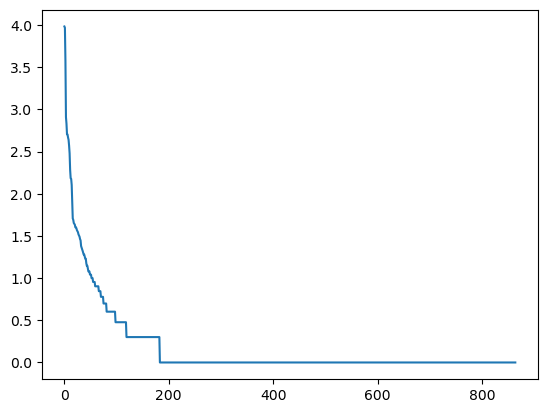

In [10]:
df_grouped = fish5.groupby('sequence', as_index = False)['reads'].sum().sort_values('reads', ascending = False)
plt.plot(np.arange(len(df_grouped)), np.log10(df_grouped['reads']))
print(f'There are {sum(df_grouped["reads"] > 10)} sequences with more than 10 reads.')

In [11]:
# Compute Levenshtein distance between every pair of reads.
distances = np.zeros((n_seqs, n_seqs))
for i in trange(n_seqs):
    for j in range(i, n_seqs):  # Only upper triangle
        d = Levenshtein.distance(unique_seqs[i], unique_seqs[j])
        distances[i, j] = d
        distances[j, i] = d  # Symmetric

100%|█████████████████████████████████████████████| 865/865 [00:00<00:00, 1140.55it/s]


In [12]:
# The `distances` matrix contains the distance between every pair of reads.
distances[:5,:5]

array([[ 0., 87., 89., 52., 59.],
       [87.,  0.,  5., 63., 59.],
       [89.,  5.,  0., 63., 57.],
       [52., 63., 63.,  0.,  7.],
       [59., 59., 57.,  7.,  0.]])

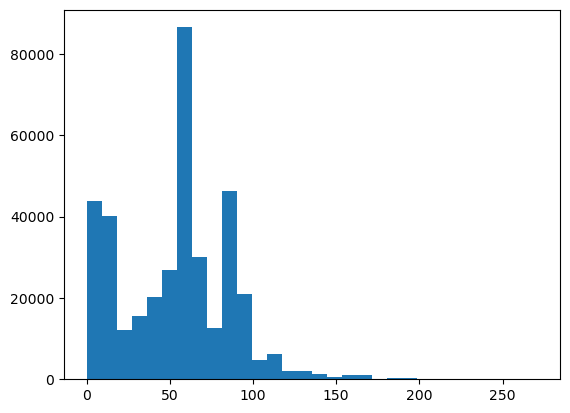

In [13]:
# Plot all the distances on a histogram. We see a bimodal distribution.
# Hopefully we can collapse all of the reads with very small distances.
plt.hist(distances[np.triu_indices(n_seqs)], bins=30);

In [14]:
# Set DBSCAN parameters
eps = 1.0  # tweak this based on your distance scale
min_samples = 2

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')

# `labels` is an array containing the cluster identity of each read.
labels = db.fit_predict(distances)

In [15]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

Cluster -1: 638 items
Cluster 0: 2 items
Cluster 1: 5 items
Cluster 2: 23 items
Cluster 3: 2 items
Cluster 4: 52 items
Cluster 5: 3 items
Cluster 6: 2 items
Cluster 7: 5 items
Cluster 8: 2 items
Cluster 9: 3 items
Cluster 10: 2 items
Cluster 11: 2 items
Cluster 12: 2 items
Cluster 13: 7 items
Cluster 14: 2 items
Cluster 15: 2 items
Cluster 16: 4 items
Cluster 17: 2 items
Cluster 18: 2 items
Cluster 19: 2 items
Cluster 20: 3 items
Cluster 21: 2 items
Cluster 22: 2 items
Cluster 23: 2 items
Cluster 24: 2 items
Cluster 25: 2 items
Cluster 26: 3 items
Cluster 27: 3 items
Cluster 28: 5 items
Cluster 29: 2 items
Cluster 30: 9 items
Cluster 31: 2 items
Cluster 32: 5 items
Cluster 33: 5 items
Cluster 34: 5 items
Cluster 35: 2 items
Cluster 36: 2 items
Cluster 37: 4 items
Cluster 38: 3 items
Cluster 39: 2 items
Cluster 40: 4 items
Cluster 41: 2 items
Cluster 42: 2 items
Cluster 43: 2 items
Cluster 44: 2 items
Cluster 45: 2 items
Cluster 46: 3 items
Cluster 47: 2 items
Cluster 48: 2 items
Cluste

<Axes: >

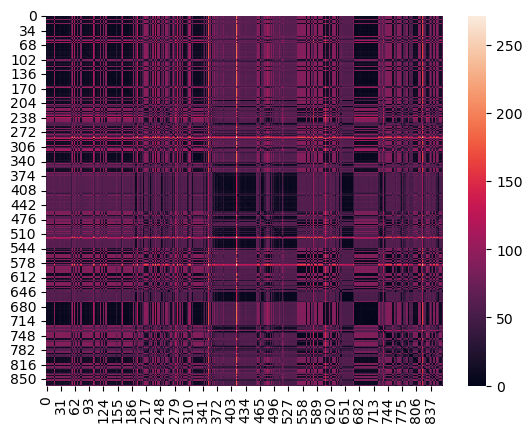

In [16]:
# Re-order the distance matrix based on the clusters and then plot.
sorted_indices = np.argsort(labels)
reordered_distances = distances[np.ix_(sorted_indices, sorted_indices)]

sns.heatmap(reordered_distances)
# The giant black square in the middle represents one cluster.

In [17]:
agg = all_data.groupby(by='barcode', as_index=False)['reads'].sum()
agg.head()

,barcode,reads
0,101D+38_101D+38_101D+38_101D+38_6D+143_NONE_NO...,1
1,101D+38_101D+38_101D+38_101D+38_6D+147_NONE_4S...,1
2,101I+38+GACTATGGAGTCGAGAGCGCGCTCGTCGACTATGGAGT...,1
3,103D+38_103D+38_103D+38_103D+38_4D+144_NONE_NO...,1
4,104D+37_104D+37_104D+37_104D+37_NONE_NONE_4S+1...,1


In [18]:
agg['reads'][agg['reads'] > 1000]

687          7321
820         10374
3889        52387
4530         2178
5638        26299
           ...   
552497       2447
552500       3149
552552       1076
552598       1159
553185    7372064
Name: reads, Length: 775, dtype: int64

In [19]:
fish5 = all_data[(all_data['fish'] == 'fish5')].copy()
fish5.head()

,barcode,fish,sample,replicate,file,reads,proportion,pass
65060,NONE_2D+62_NONE_NONE_NONE_87D+167_87D+167_87D+...,fish5,1,1,fish5_s1_rep1,6357,0.574514,True
65061,54D+36_54D+36_54D+36_NONE_NONE_NONE_NONE_NONE_...,fish5,1,1,fish5_s1_rep1,1331,0.120289,True
65062,NONE_NONE_NONE_NONE_108D+142_108D+142_108D+142...,fish5,1,1,fish5_s1_rep1,783,0.070764,True
65063,3D+37_NONE_NONE_NONE_NONE_89D+168_89D+168_89D+...,fish5,1,1,fish5_s1_rep1,537,0.048531,True
65064,NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE,fish5,1,1,fish5_s1_rep1,380,0.034343,True


In [20]:
fish5['sequence'] = fish5['barcode'].apply(lambda x: br.get_sequence(x, reference_seq).upper())

In [21]:
df_grouped = fish5.groupby(['sequence', 'barcode'], as_index = False)['reads'].sum().sort_values('reads', ascending = False).reset_index(drop=True)
unique_seqs = np.array(df_grouped['sequence'])
n_seqs = len(unique_seqs)

print(f'There are {len(fish5["sequence"])} sequences in this data, {n_seqs} of which are unique.')

There are 36477 sequences in this data, 22926 of which are unique.


In [22]:
df_grouped.head()

,sequence,barcode,reads
0,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCCTATGGAGTC...,2D+36_81D+61_81D+61_81D+61_81D+61_NONE_NONE_NO...,366102
1,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE,291373
2,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_2D+62_NONE_NONE_NONE_87D+167_87D+167_87D+...,239447
3,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACGATGGAG...,54D+36_54D+36_54D+36_NONE_NONE_NONE_NONE_NONE_...,185179
4,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGGAGTCGAGA...,87D+36_87D+36_87D+36_87D+36_NONE_1D+172_NONE_N...,18979


There are 628 sequences with more than 10 reads.


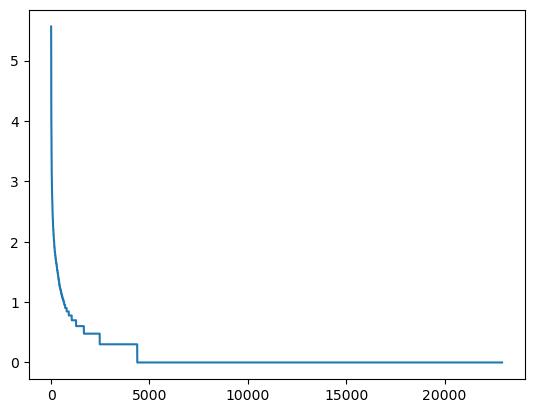

In [23]:
plt.plot(np.arange(len(df_grouped)), np.log10(df_grouped['reads']))
print(f'There are {sum(df_grouped["reads"] > 10)} sequences with more than 10 reads.')

In [24]:
# Compute Levenshtein distance between every pair of reads.
distances = np.zeros((n_seqs, n_seqs))
for i in trange(n_seqs):
    for j in range(i, n_seqs):  # Only upper triangle
        d = Levenshtein.distance(unique_seqs[i], unique_seqs[j])
        distances[i, j] = d
        distances[j, i] = d  # Symmetric

100%|███████████████████████████████████████████| 22926/22926 [09:43<00:00, 39.27it/s]


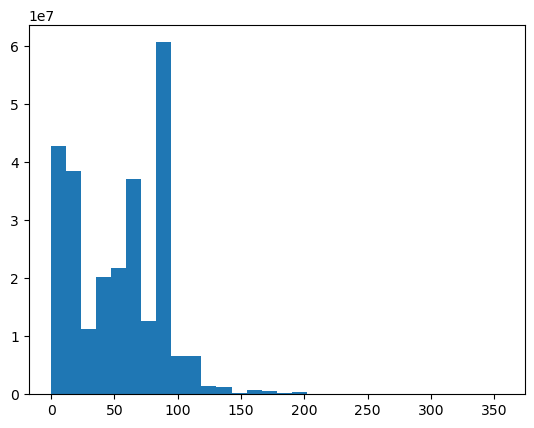

In [25]:
# Plot all the distances on a histogram. We see a bimodal distribution.
# Hopefully we can collapse all of the reads with very small distances.
plt.hist(distances[np.triu_indices(n_seqs)], bins=30);

In [26]:
# Set DBSCAN parameters
eps = 1.0  # tweak this based on your distance scale
min_samples = 10

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')

# `labels` is an array containing the cluster identity of each read.
labels = db.fit_predict(distances)

In [27]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

Cluster -1: 22352 items
Cluster 0: 44 items
Cluster 1: 262 items
Cluster 2: 22 items
Cluster 3: 65 items
Cluster 4: 11 items
Cluster 5: 13 items
Cluster 6: 22 items
Cluster 7: 23 items
Cluster 8: 14 items
Cluster 9: 10 items
Cluster 10: 18 items
Cluster 11: 10 items
Cluster 12: 14 items
Cluster 13: 10 items
Cluster 14: 7 items
Cluster 15: 11 items
Cluster 16: 11 items
Cluster 17: 7 items


In [41]:
df_grouped[labels == 0].sort_values('reads', ascending=False).head()

,sequence,barcode,reads
0,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCCTATGGAGTC...,2D+36_81D+61_81D+61_81D+61_81D+61_NONE_NONE_NO...,366102
19,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCTATGGAGTCG...,3D+35_81D+61_81D+61_81D+61_81D+61_NONE_NONE_NO...,4304
22,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCCTATGGAGTC...,2D+36_81D+61_81D+61_81D+61_81D+61_1D+172_NONE_...,2770
38,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCCTATGGAGTC...,2D+36_81D+61_81D+61_81D+61_81D+61_NONE_NONE_NO...,901
42,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCTATGGAGTCG...,3D+35_81D+66_81D+66_81D+66_81D+66_NONE_NONE_NO...,761


In [29]:
for cluster in np.unique(labels):
    if cluster == -1: continue
        
    cluster_df = df_grouped[labels == cluster]
    indices = np.array(cluster_df.index)
    
    max_distance = np.max(distances[np.ix_(indices, indices)])
    print(f'The max distance between sequences in cluster {cluster} is {max_distance}.')
    print(f'The most frequent sequences in this cluster have read counts {cluster_df.iloc[0:4]["reads"].values}.')

    winner_seq = cluster_df.iloc[0]["sequence"]
    # print(f'The winner sequence in this cluster is {winner_seq}.')

The max distance between sequences in cluster 0 is 3.0.
The most frequent sequences in this cluster have read counts [366102   4304   2770    901].
The winner sequence in this cluster is AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCCTATGGAGTCGAGAGCGCGCTCGTCGAGTATGGAGTCGACTACAGTCGCTACGACTATGGAGTCGACAGAGATATCATGCAGTATGGAGTCGACAGCAGTATCTGCTGTCATGGAGTCGACTGCACGACAGTCGACTATGGAGTCGCGAGCGCTATGAGCGACTATGGGCATGCAATTAAGTCTCAGCCACCGTTAACTGAACATGTCAAAACC.
The max distance between sequences in cluster 1 is 8.0.
The most frequent sequences in this cluster have read counts [291373  15753   8547   4558].
The winner sequence in this cluster is AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAGTCGAGAGCGCGCTCGTCGACTATGGAGTCGTCAGCAGTACTACTGACGATGGAGTCGACAGCAGTGTGTGAGTCTATGGAGTCGAGAGCATAGACATCGAGTATGGAGTCGACTACAGTCGCTACGACTATGGAGTCGACAGAGATATCATGCAGTATGGAGTCGACAGCAGTATCTGCTGTCATGGAGTCGACTGCACGACAGTCGACTATGGAGTCGCGAGCGCTATGAGCGACTATGGGCATGCAATTAAGTCTCAGCCACCGTTAACTGAACATGTCAAAACC.
The max distance between sequences in c

In [69]:
len(df_grouped[df_grouped['reads'] >= 10])

661

In [70]:
# Set DBSCAN parameters
eps = 1.0  # tweak this based on your distance scale
min_samples = 2

db = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed')

# `labels` is an array containing the cluster identity of each read.
labels = db.fit_predict(distances[:661,:661])

In [71]:
# Print size of each cluster
unique_labels, cluster_counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, cluster_counts):
    print(f"Cluster {label}: {count} items")

Cluster -1: 286 items
Cluster 0: 48 items
Cluster 1: 70 items
Cluster 2: 14 items
Cluster 3: 31 items
Cluster 4: 5 items
Cluster 5: 4 items
Cluster 6: 12 items
Cluster 7: 19 items
Cluster 8: 16 items
Cluster 9: 3 items
Cluster 10: 4 items
Cluster 11: 3 items
Cluster 12: 9 items
Cluster 13: 4 items
Cluster 14: 3 items
Cluster 15: 6 items
Cluster 16: 4 items
Cluster 17: 2 items
Cluster 18: 3 items
Cluster 19: 12 items
Cluster 20: 3 items
Cluster 21: 3 items
Cluster 22: 2 items
Cluster 23: 9 items
Cluster 24: 2 items
Cluster 25: 2 items
Cluster 26: 2 items
Cluster 27: 2 items
Cluster 28: 3 items
Cluster 29: 2 items
Cluster 30: 2 items
Cluster 31: 2 items
Cluster 32: 2 items
Cluster 33: 2 items
Cluster 34: 3 items
Cluster 35: 2 items
Cluster 36: 4 items
Cluster 37: 2 items
Cluster 38: 2 items
Cluster 39: 3 items
Cluster 40: 2 items
Cluster 41: 2 items
Cluster 42: 2 items
Cluster 43: 2 items
Cluster 44: 3 items
Cluster 45: 3 items
Cluster 46: 2 items
Cluster 47: 2 items
Cluster 48: 2 items


In [76]:
distances[np.ix_(labels == -1, labels == -1)]

array([[ 0., 31., 76., ..., 38., 73., 47.],
       [31.,  0., 81., ..., 18., 74., 45.],
       [76., 81.,  0., ..., 83., 19., 58.],
       ...,
       [38., 18., 83., ...,  0., 84., 59.],
       [73., 74., 19., ..., 84.,  0., 39.],
       [47., 45., 58., ..., 59., 39.,  0.]])

In [61]:
for cluster in np.unique(labels):
    if cluster == -1: continue
        
    cluster_df = df_grouped.iloc[:100][labels == cluster]
    indices = np.array(cluster_df.index)
    
    max_distance = np.max(distances[np.ix_(indices, indices)])
    print(f'The max distance between sequences in cluster {cluster} is {max_distance}.')
    print(f'The most frequent sequences in this cluster have read counts {cluster_df.iloc[0:4]["reads"].values}.')

    winner_seq = cluster_df.iloc[0]["sequence"]
    # print(f'The winner sequence in this cluster is {winner_seq}.')

The max distance between sequences in cluster 0 is 3.0.
The most frequent sequences in this cluster have read counts [366102   4304   2770    901].
The max distance between sequences in cluster 1 is 4.0.
The most frequent sequences in this cluster have read counts [291373  15753   4558   2957].
The max distance between sequences in cluster 2 is 1.0.
The most frequent sequences in this cluster have read counts [239447    883].
The max distance between sequences in cluster 3 is 2.0.
The most frequent sequences in this cluster have read counts [185179   6781   2061   1228].
The max distance between sequences in cluster 4 is 2.0.
The most frequent sequences in this cluster have read counts [18979  2149  1578].
The max distance between sequences in cluster 5 is 1.0.
The most frequent sequences in this cluster have read counts [13498  1217].
The max distance between sequences in cluster 6 is 3.0.
The most frequent sequences in this cluster have read counts [13432 11420 11165   311].
The max 

In [85]:
np.sum(distances == 1, axis = 0)[:100]

array([31, 98, 21, 37, 10, 25, 12, 11,  7, 13, 12, 27, 14, 14,  2,  7,  5,
        5, 20, 15, 10, 20,  7,  8,  8, 15, 21,  3,  9,  6,  8, 15,  9, 15,
       10, 13,  4,  6,  7,  4,  0,  5,  7, 13,  5,  3,  3,  8,  4,  6,  5,
        2,  7,  2,  5,  4,  1,  3,  8,  5,  8,  8,  6,  3,  5,  5,  8,  9,
        3,  3,  4,  5,  6,  6, 10,  0,  6,  4,  2,  6,  6, 10,  2,  9,  9,
        3,  2,  3,  6,  3,  3, 14,  3,  1, 10,  6,  3,  1,  4,  6])

In [105]:
df_grouped[np.sum(distances[:100, :] == 1, axis = 0) == 1]

,sequence,barcode,reads
2,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_2D+62_NONE_NONE_NONE_87D+167_87D+167_87D+...,239447
4,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGGAGTCGAGA...,87D+36_87D+36_87D+36_87D+36_NONE_1D+172_NONE_N...,18979
7,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...,1D+38_NONE_NONE_NONE_NONE_6D+167_NONE_NONE_NON...,13498
8,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_NONE_NONE_NONE_1D+146_81D+170_81D+170_81D...,13432
12,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_NONE_NONE_NONE_NONE_87D+167_87D+167_87D+1...,8248
...,...,...,...
22299,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_1I+66+G_NONE_NONE_NONE_NONE_NONE_NONE_NON...,1
22365,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_1I+65+C_NONE_NONE_NONE_NONE_NONE_NONE_NON...,1
22429,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_81D+66_81D+66_81D+66_81D+66_1D+172_NONE_N...,1
22562,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_1I+64+A_NONE_NONE_NONE_NONE_NONE_NONE_NON...,1


In [99]:
df_grouped.iloc[[1,5,26]]

,sequence,barcode,reads
1,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE,291373
5,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...,1D+38_1D+64_NONE_NONE_NONE_NONE_NONE_NONE_NONE...,15753
26,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...,1D+38_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_...,1809


In [112]:
fish5[fish5['barcode'] == '1D+38_1D+64_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE']

,barcode,fish,sample,replicate,file,reads,proportion,pass,sequence
65074,1D+38_1D+64_NONE_NONE_NONE_NONE_NONE_NONE_NONE...,fish5,1,1,fish5_s1_rep1,35,0.003163,True,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...
65430,1D+38_1D+64_NONE_NONE_NONE_NONE_NONE_NONE_NONE...,fish5,1,2,fish5_s1_rep2,17,0.001018,True,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...
65942,1D+38_1D+64_NONE_NONE_NONE_NONE_NONE_NONE_NONE...,fish5,1,3,fish5_s1_rep3,17,0.001200,True,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...
66402,1D+38_1D+64_NONE_NONE_NONE_NONE_NONE_NONE_NONE...,fish5,2,1,fish5_s2_rep1,136,0.006492,True,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...
67107,1D+38_1D+64_NONE_NONE_NONE_NONE_NONE_NONE_NONE...,fish5,2,2,fish5_s2_rep2,214,0.008480,True,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...
68006,1D+38_1D+64_NONE_NONE_NONE_NONE_NONE_NONE_NONE...,fish5,2,3,fish5_s2_rep3,260,0.010462,True,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...
68773,1D+38_1D+64_NONE_NONE_NONE_NONE_NONE_NONE_NONE...,fish5,3,1,fish5_s3_rep1,525,0.149105,True,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...
69321,1D+38_1D+64_NONE_NONE_NONE_NONE_NONE_NONE_NONE...,fish5,3,2,fish5_s3_rep2,787,0.093446,True,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...
70313,1D+38_1D+64_NONE_NONE_NONE_NONE_NONE_NONE_NONE...,fish5,3,3,fish5_s3_rep3,809,0.094864,True,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...
71406,1D+38_1D+64_NONE_NONE_NONE_NONE_NONE_NONE_NONE...,fish5,5,1,fish5_s5_rep1,337,0.018661,True,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...


In [101]:
distances[np.ix_([1,5,26],[1,5,26])]

array([[0., 2., 1.],
       [2., 0., 1.],
       [1., 1., 0.]])

In [97]:
distances[:10,26]

array([82.,  1., 90., 53., 87.,  1., 62.,  6., 83., 82.])

In [93]:
df_grouped[distances[7,:] == 1]

,sequence,barcode,reads
35,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACTATGGAG...,NONE_NONE_NONE_NONE_NONE_6D+167_NONE_NONE_NONE...,1217
141,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...,1D+38_NONE_NONE_NONE_1I+145+A_6D+167_NONE_NONE...,111
261,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGCTATGGAGT...,1D+37_NONE_NONE_NONE_NONE_6D+167_NONE_NONE_NON...,45
343,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...,1D+38_1D+64_NONE_NONE_NONE_6D+167_NONE_NONE_NO...,29
405,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...,1D+38_NONE_NONE_NONE_NONE_6D+167_NONE_NONE_1D+...,21
410,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...,1D+38_NONE_NONE_NONE_1D+145_6D+167_NONE_NONE_N...,21
447,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGACATGGAGT...,1D+39_NONE_NONE_NONE_NONE_6D+167_NONE_NONE_NON...,17
494,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...,1D+38_NONE_NONE_NONE_NONE_6D+167_NONE_NONE_1D+...,15
1063,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...,1D+38_NONE_NONE_NONE_NONE_6D+166_NONE_NONE_NON...,5
11495,AGATCTCGAGCTCAAGCTTCGGACAGCAGTATCATCGATATGGAGT...,1D+38_NONE_NONE_NONE_NONE_7D+170_NONE_NONE_NON...,1


In [65]:
top_sequence = df_grouped['sequence'][0]
np.sum(distances[0:10,:100] < 2, axis = 0)

array([1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 1, 1, 0, 2, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 2, 0, 0, 1, 0, 0, 0, 0, 0])

In [30]:
indices

array([ 759, 1056, 1229, 6405, 6425, 6449, 7932])

In [31]:
d = distances[21424,:]
np.where(d == 1)[0]

array([], dtype=int64)

In [32]:
distances[21424,2798]

np.float64(8.0)

In [33]:
Levenshtein.distance(unique_seqs[14703], unique_seqs[13850])

10

In [34]:
labels[2798]

np.int64(-1)